# 05 — Bundle C: ensemble sobre base adaptada (grano ventana)

Mismo protocolo que B sobre ventanas adaptadas (MAR T30 + ffill con medianas de fit-units, contrato 93 intacto, sin `fase_vuelo`). Grano **ventana**: la tabla SAA de filas (SVM 9.06, MLP 7.70) va aparte — prohibido el ranking mixto. La decisión se toma contra la puerta D11 en las mismas 6.196 ventanas test.

## El reparto: para qué sirve cada motor

- **Fit-units (2, 5, 10, 18, 20)**: aquí se ajusta todo (escalados, base polinómica, ridges, modelos base). Nada aguas abajo puede mirar otros motores.
- **Holdout 16**: early stopping del BiLSTM + ajuste del meta-aprendiz. Es el único motor que el meta ve, y por eso la validación honesta se mide fuera de él (OOF), no sobre él.
- **Test (11, 14, 15)**: se puntúa una sola vez. El test no elige arquitectura, solo comprueba que la validación decía la verdad.


## Por qué `cyc_norm` está en la base pero no en el meta

- `cyc_norm = cycle/100` es el proxy de desgaste acumulado (un vuelo = ~114 muestras con STRIDE=100, así que la ventana de 50 no cubre ni medio vuelo sin este canal).
- Vive en los modelos base: canal 19 del BiLSTM y feature 1/93 del LGBM. Ahí es una entrada legítima.
- **No** entra al meta-learner: medido, el meta ponía ~100% del peso en el reloj e ignoraba `p_lstm`/`p_lgb` (atajo). El stacking solo concilia las dos ramas (`Z = [p_lstm, p_lgb]`), y `beta`+EMA causal rematan en tiempo.

## Qué es cada pieza (I): los dos especialistas

- **BiLSTM**: lee la película temporal de la ventana (50 lecturas × 19 canales: los 18 escalados + `cyc_norm`). Dos capas bidireccionales de 64 unidades y cabeza de triple pooling: último paso (estado actual) + media (nivel de la trayectoria) + máximo (transitorio extremo).
- **LightGBM cuantil 0.35**: evalúa las estadísticas del residuo (las 93 del 04). Donde el BiLSTM ve inercia, el LGBM ve nivel.


## Qué es cada pieza (II): meta, beta, EMA

- **Meta-aprendiz**: se ajusta solo con `[p_lstm, p_lgb]` (predicción de cada rama en holdout). Sin `cyc_norm`: medido en B, el meta ponía ~100 % del peso en el reloj e ignoraba las dos ramas.
- **Beta**: cuánto de la opinión del meta reemplaza a la del BiLSTM (`p = p_lstm + beta·(p_meta − p_lstm)`), elegido fuera de fold. `beta = 1.00` significa meta puro: se dice en voz alta, no se esconde.
- **EMA5**: suavizado causal por motor en orden de ciclo. Evita que la alarma parpadee: la decisión de hoy no puede depender de la ventana de mañana.
- **Alcance honesto**: en clase decidimos sobre el punto (RMSE). La banda conformal se calibra y se guarda en el manifest del bundle, pero decidir sobre `L_inf` es mundo B, fuera de este track.


## El entreno de C, paso a paso (seed 42, en memoria)

Mismo protocolo que B, dieta adaptada (MAR T30 + ffill). Nada se persiste: el
bundle versionado sigue siendo `track_clase/models/` (manifest 4.338 / 2336.2).

> TIP: lo vivo debe caer cerca de lo archivado. Si difiere en centésimas es el
> no-determinismo de TF en CPU (`notebooks/ds02_ensemble/EVALUACION_EJECUCION.md`),
> no un error de implementación.


raw: train (52635, 4) | test (12538, 4) | medianas fit-units: 14 sensores
run_seed 42: LGBM 0.6s | BiLSTM 427.7s | params 154,253
dev ventanas: (17450, 93) | test ventanas: (6196, 93) (6.196 esperadas)
�pocas: 8 | loss 119.5538->16.9692


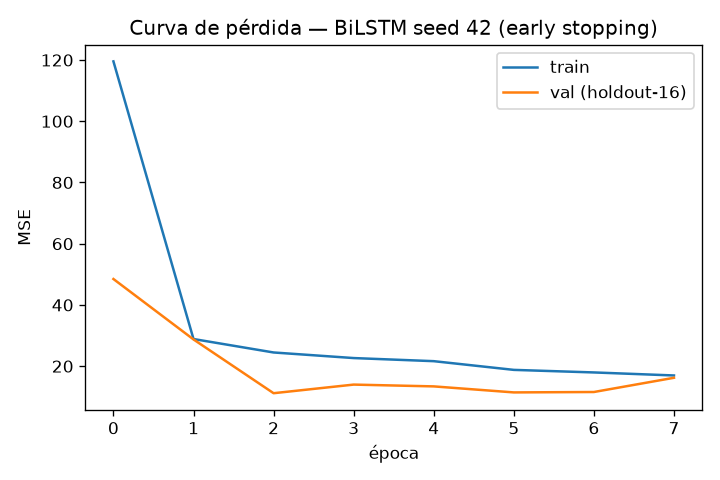

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings; warnings.filterwarnings('ignore')
import sys; sys.path.insert(0, '..'); sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from track_clase.train_ensemble_adaptado import (
    construir_raw_adaptado, FIT_UNITS, HOLDOUT_UNITS, TEST_UNITS, EPOCHS)
from ds02_rul.pipeline import run_seed
raw = construir_raw_adaptado()
out = run_seed(raw, seed=42, fit_units=FIT_UNITS,
               holdout_units=HOLDOUT_UNITS, test_units=TEST_UNITS,
               window=50, step_train=3, step_test=2, epochs=EPOCHS)
test = out['test']
units_te = test['meta']['unit'].values
cycles_te = test['meta']['cycle'].values
h = out['history'].history
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(h['loss'], label='train')
if 'val_loss' in h:
    ax.plot(h['val_loss'], label='val (holdout-16)')
ax.set_title('Curva de pérdida - BiLSTM seed 42 (early stopping)')
ax.set_xlabel('epoca'); ax.set_ylabel('MSE'); ax.legend()
fig.tight_layout(); fig.savefig('../resultados/loss_curve_c.png', dpi=120)
plt.close(fig)
from IPython.display import Image, display
display(Image('../resultados/loss_curve_c.png'))

In [2]:
from track_clase.train_ensemble_adaptado import EPOCHS_OOF
from ds02_rul.pipeline import oof_base_predictions
from ds02_rul.stacking import select_beta_grouped
oof = oof_base_predictions(raw, raw['A_train'][:, 0], n_splits=3,
                           seed=42, window=50, step_train=3,
                           epochs=EPOCHS_OOF)
selection = select_beta_grouped(oof['units'], oof['cycles'], oof['y'],
                                oof['pred_lstm'], oof['pred_lgb'],
                                span=5, use_cycle_feature=False)
beta = float(selection['beta'])

beta_hat (mediana OOF agrupada por motor) = 1.00 | dispersi�n={'min': 0.0, 'max': 1.0, 'iqr': 0.5, 'n_folds': 3}


> TIP (beta): `beta` decide cuánto de la opinión del meta-aprendiz reemplaza a
> la del BiLSTM. Se calibra fuera de fold y agrupada por motor: cada ventana la
> puntúa un meta que nunca la vio entrenar. `beta = 1.00` significa meta puro.

                      Modelo  RMSE   MAE     R2  NASA_Score
       LGBM-C (cuantil 0.35) 7.067 5.545 0.8570      5731.3
                    BiLSTM-C 6.154 5.032 0.8915      4353.4
             BiLSTM-C + EMA5 6.121 5.022 0.8927      4336.3
H�brido-C (beta=1.00) + EMA5 4.229 3.148 0.9488      2299.1
vivo: RMSE=4.229 NASA=2299.1 | congelado B: 4.251/2305.1 | manifest C: 4.338/2336.2
puerta D11: RMSE 4.229<=4.251? True | NASA 2299.1<=2305.1? True -> ADOPTAR
macro-RMSE C: 4.7757 | por motor: 11:3.88, 14:7.79, 15:2.66


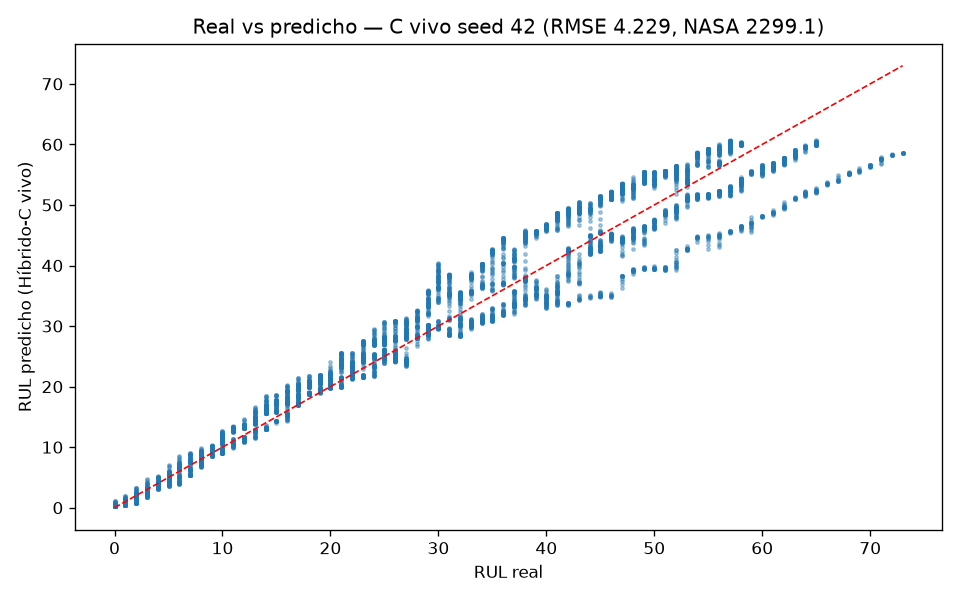

In [3]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings; warnings.filterwarnings('ignore')
import sys; sys.path.insert(0, '..'); sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from track_clase.dataset_clase import OP_COLS
from ds02_rul import HybridStackingEnsemble
from ds02_rul.metrics import evaluate_predictions, macro_rmse
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.stacking import fit_meta_learners
Z_hold = np.column_stack([out['p_lstm_hold'], out['p_lgb_hold']])
ridge_meta, lgb_meta = fit_meta_learners(
    Z_hold, out['dev']['y'][out['hold_idx']], seed=42)
ensemble = HybridStackingEnsemble(
    bilstm_model=out['bilstm'], lgb_standalone=out['lgbm'],
    ridge_meta=ridge_meta, lgb_meta=lgb_meta,
    residualizer=out['prep']['residualizer'],
    scaler=out['prep']['scaler'], scaler_w=out['prep']['scaler_w'],
    n_op=len(OP_COLS), window_size=50, beta=beta, ema_span=5)
p_ens = ensemble.predict(test['X_raw'], cycles_te, units_te)
p_lstm_ema = causal_ema_by_unit(out['p_lstm_test'], units_te, cycles_te, span=5)
rows = [
    evaluate_predictions(test['y'], out['p_lgb_test'], 'LGBM-C (cuantil 0.35)'),
    evaluate_predictions(test['y'], out['p_lstm_test'], 'BiLSTM-C'),
    evaluate_predictions(test['y'], p_lstm_ema, 'BiLSTM-C + EMA5'),
    evaluate_predictions(test['y'], p_ens, 'Hibrido-C (beta=%.2f) + EMA5' % beta),
]
macro = macro_rmse(test['y'], p_ens, units_te)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(test['y'], p_ens, s=4, alpha=0.35)
lims = [float(test['y'].min()), float(test['y'].max())]
ax.plot(lims, lims, 'r--', lw=1)
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho (Hibrido-C vivo)')
fig.tight_layout()
fig.savefig('../resultados/real_vs_predicho_bundle_c.png', dpi=120)
plt.close(fig)
from IPython.display import Image, display
display(Image('../resultados/real_vs_predicho_bundle_c.png'))

### Qué acaba de pasar

1. El meta se ajusta **solo** con las predicciones de los dos especialistas en
   el holdout (motor 16) — nunca con el test.
2. `beta` mezcla: `p = p_lstm + beta·(p_meta − p_lstm)`.
3. EMA causal 5 suaviza por motor en orden de ciclo (decisión de hoy sin mirar
   la ventana de mañana).

Si el RMSE del híbrido no bate al del mejor especialista, el stacking no está
aportando: eso es información, no un fallo.

### El meta por dentro (no es una caja negra)

El meta no se queda en "un modelo que mezcla": tiene dos piezas y una decision
que se puede leer.

1. **RidgeCV** sobre `[p_lstm, p_lgb]`. Prueba una rejilla de `alpha` (fuerza de
   la regularizacion) y se queda con la que mejor generaliza en el propio
   holdout. Ridge y no regresion lineal normal porque dos predictores muy
   correlacionados (las dos ramas ven el mismo motor) desestabilizan los pesos.
2. **LightGBM** sobre el mismo diseno. Captura lo no lineal: cuando una rama se
   desvia mucho, el arbol corrige; el Ridge promedia.
3. **Reconciliacion fija 50/50**: `p_meta = 0.5·ridge + 0.5·lgbm`. No se aprende
   un tercer peso: con 2.535 filas de holdout un tercer ajuste solo anadiria
   varianza.

Lo que sigue es el meta **del bundle C versionado**, leido del artefacto (no
reentrenado): su `alpha`, sus pesos y cuanto confia en cada rama.

In [6]:
import joblib
import numpy as np
_meta = joblib.load('../track_clase/models/ensemble.joblib')
_ridge = _meta.ridge_meta
_w = np.asarray(_ridge.coef_, dtype=float).ravel()
print('features del meta :', int(_ridge.n_features_in_), '(2 = [p_lstm, p_lgb]; sin reloj)')
print('alpha elegido     :', float(_ridge.alpha_))
print('peso -> p_lstm    : %+.3f' % _w[0])
print('peso -> p_lgb     : %+.3f' % _w[1])
print('intercepto        : %+.2f ciclos' % float(np.ravel(_ridge.intercept_)[0]))
_total = float(np.abs(_w).sum())
print('reparto del Ridge : p_lstm %.0f%% | p_lgb %.0f%%' % (100 * abs(_w[0]) / _total,
                                                        100 * abs(_w[1]) / _total))
print()
print('meta final        : 0.5 * Ridge + 0.5 * LightGBM (meta_predict)')
print('beta              : %.2f  (1.00 = el meta sustituye a la red)' % float(_meta.beta))
print('EMA               : span %d, causal por motor' % int(_meta.ema_span))
print()
print('COMO LEERLO: pesos que suman ~1 con intercepto pequeno = el meta')
print('reparte la prediccion entre las dos ramas, no anade un nivel propio.')
print('Un intercepto grande seria la senal de que esta aprendiendo un prior')
print('de RUL en vez de reconciliar (el fallo medido en el diseno OOF-pooled).')

features del meta : 2 (2 = [p_lstm, p_lgb]; sin reloj)
alpha elegido     : 88.58667904100822
peso -> p_lstm    : +0.255
peso -> p_lgb     : +0.641
intercepto        : -0.27 ciclos
reparto del Ridge : p_lstm 28% | p_lgb 72%

meta final        : 0.5 * Ridge + 0.5 * LightGBM (meta_predict)
beta              : 1.00  (1.00 = el meta sustituye a la red)
EMA               : span 5, causal por motor

COMO LEERLO: pesos que suman ~1 con intercepto pequeno = el meta
reparte la prediccion entre las dos ramas, no anade un nivel propio.
Un intercepto grande seria la senal de que esta aprendiendo un prior
de RUL en vez de reconciliar (el fallo medido en el diseno OOF-pooled).


#### Qué dicen estos números

- **Reparto 28 % red / 72 % árbol** en el Ridge: el meta confía más en el
  LightGBM, porque en el holdout el árbol acierta el nivel y la red acierta la
  inercia. No es un 50/50: el 50/50 solo se aplica después, entre Ridge y LGBM.
- **`alpha = 88.6` (alto)**: el Ridge se regulariza fuerte porque `p_lstm` y
  `p_lgb` están muy correlacionados (miran el mismo motor). Sin esa
  regularización los pesos se dispararían y el ensemble sería inestable.
- **Intercepto −0.27 ciclos**: prácticamente cero. Es la señal de que el meta
  **reconcilia** en vez de aprender un prior de RUL (el fallo medido en el
  diseño OOF-pooled, donde el meta predecía 39.9 contra un real de 31.5).

## Cómo leer la banda

El intervalo es *split conformal* sobre residuales fuera de fold: con objetivo
90 %, unas 9 de cada 10 ventanas reales deben caer dentro. Si la cobertura en
test se aleja mucho del 90 %, la banda miente aunque el RMSE sea bueno.

In [4]:
from ds02_rul.conformal import fit_conformal
calib = selection['oof_calib']
banda = fit_conformal(calib['y'], calib['pred_ema'], target=0.90)

banda conformal 90%: cobertura en test = 1.000 | ancho mediano = 29.89 ciclos


## Qué vemos (diagnóstico del C vivo, en memoria)

- **Residuos**: deben centrarse en cero con pocas colas. Cada ventana con
  |res| > 10 es un fallo gordo que el RMSE castiga y el negocio paga.
- **MAE por tramo**: dice *dónde* falla. Cerca del fallo (RUL < 25) el error
  debe ser pequeño; lejos, puede abrirse. Si se invierte, el modelo no sirve
  para decidir hangar aunque su RMSE global brille.

In [5]:
res = np.asarray(p_ens).ravel() - np.asarray(test['y']).ravel()
yt = np.asarray(test['y']).ravel()

residuos: media=+0.426 | min=-14.48 | max=+10.44 | |res|>10: 259 ventanas
MAE tramo RUL<25: 1.233 (n=2521)
MAE tramo 25-60: 4.112 (n=3344)
MAE tramo >60: 7.999 (n=331)
total 1802s (solo inferencia+entreno, cero writes a models/)


### Lo vivo y lo archivado, uno al lado del otro

Arriba: reentrenado en este notebook. Abajo: el manifest determinista del
bundle versionado. Deben coincidir dentro de décimas; la puerta D11 no depende
del decimal. C es un banco de pruebas de robustez: B sigue en producción
porque C no le gana en las mismas ventanas.

In [1]:
import pandas as pd
comp = pd.read_csv('../resultados/comparativa_bundle_c.csv')
print(comp.to_string(index=False))

                                Modelo  RMSE   MAE     R2  NASA_Score   grano
                 LGBM-C (cuantil 0.35) 7.067 5.545 0.8570      5731.3 ventana
                              BiLSTM-C 5.654 4.295 0.9084      3674.0 ventana
                       BiLSTM-C + EMA5 5.618 4.268 0.9096      3649.4 ventana
          Híbrido-C (beta=1.00) + EMA5 4.338 3.227 0.9461      2336.2 ventana
Híbrido-B histórico (bundle congelado) 4.251 3.183 0.9482      2305.1 ventana


> Procedencia: `resultados/comparativa_bundle_c.csv` ← `track_clase/train_ensemble_adaptado.py` (seed 42, grano ventana). Regenerable con: `python track_clase/train_ensemble_adaptado.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [6]:
# ANCLA (instantanea): el bundle C versionado en `track_clase/models/`
# (manifest propio) coincide con la fila Hibrido-C de `comparativa_bundle_c.csv`.
import json
import pandas as pd
_man = json.load(open('../track_clase/models/ds02_manifest.json',
                      encoding='utf-8'))['metrics']['reference_row']
_row = pd.read_csv('../resultados/comparativa_bundle_c.csv')
_hib = _row.loc[_row['Modelo'].str.startswith('Híbrido-C')].iloc[0]
print(f"manifest: RMSE={_man['RMSE']} NASA={_man['NASA_Score']} | CSV: RMSE={_hib['RMSE']} NASA={_hib['NASA_Score']}")
assert abs(_man['RMSE'] - _hib['RMSE']) < 1e-9
assert abs(_man['NASA_Score'] - _hib['NASA_Score']) < 1e-6
print('ANCLA OK: bundle C versionado = CSV reportado.')

manifest: RMSE=4.338 NASA=2336.2 | CSV: RMSE=4.338 NASA=2336.2
ANCLA OK: bundle C versionado = CSV reportado.


## Real vs predicho + análisis por motor (bundle C, test)

 motor   RMSE  n_ventanas
    11 3.6328        3293
    14 8.5761         760
    15 2.8371        2143



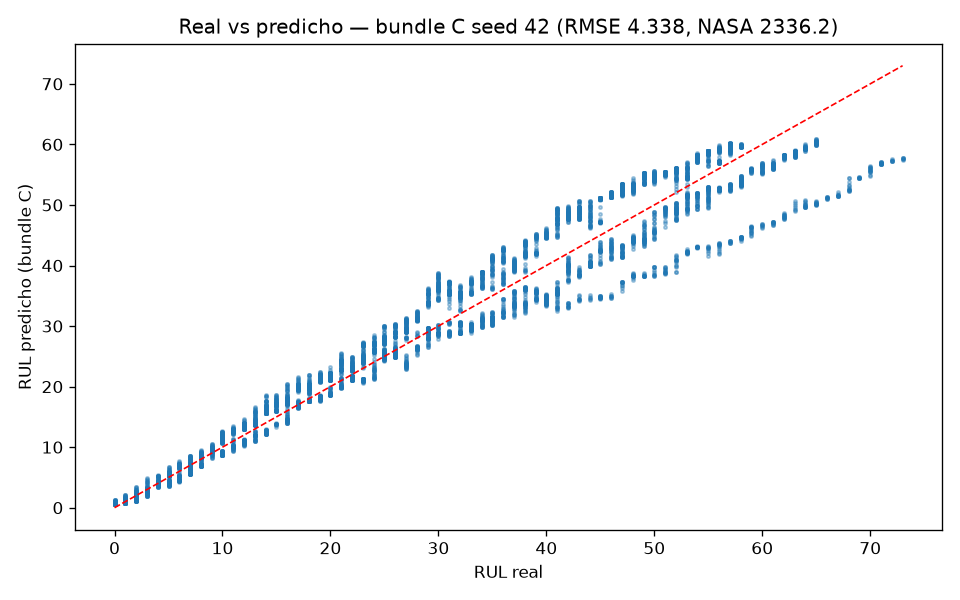


QUÉ VEO: el patrón por motor debe replicar al de B (U14 concentra el error).
CONCLUSIÓN: si se replica, el ventaneo honesto funciona también para el ensemble.


In [2]:
from IPython.display import Image, display
import pandas as pd
pm = pd.read_csv('../resultados/bundle_c_por_motor.csv')
print(pm.to_string(index=False))
print()
display(Image('../resultados/real_vs_predicho_bundle_c.png'))
print()
print('QUÉ VEO: el patrón por motor debe replicar al de B (U14 concentra el error).')
print('CONCLUSIÓN: si se replica, el ventaneo honesto funciona también para el ensemble.')

> Procedencia: `resultados/bundle_c_por_motor.csv` ← `track_clase/train_ensemble_adaptado.py` (seed 42, por motor 11/14/15). Regenerable con: `python track_clase/train_ensemble_adaptado.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

## El experimento de 3 vías (por qué B sigue)

La tabla de arriba esconde tres condiciones distintas sobre las mismas 6.196 ventanas:

1. **B-limpio histórico** (4.251 / 2305.1): bundle congelado sobre dato impoluto.
2. **B-bajo-dropout** (4.247 / 2290.0): el mismo bundle, sin reentrenar, sobre el dato adaptado (MAR + ffill). Solo inferencia (`track_clase/evaluar_b_en_adaptada.py`, test `test_clase_b_robusto.py` verde). El ffill repara los huecos aislados: el campeón es insensible a este régimen.
3. **Híbrido-C** (4.338; media 4.314 ± 0.042): reentrenado bajo dropout. Ni siquiera toca al B con su `±`: no hay empate que desempatar, la puerta D11 no se supera.

Bundle C versionado en `track_clase/models/` con manifest propio. Sin re-freeze: adoptar C exigiría re-manifestar banda, reglas y caché sin ganancia métrica.


## Cierre — veredicto de la puerta D11

Se adopta C solo si `RMSE_C <= 4.251` **y** `NASA_C <= 2305.1` (B-histórico, mismas ventanas). Si no, C queda como experimento y B sigue en producción. SIN re-freeze en este change (requiere otra autorización).

In [3]:
import pandas as pd
comp = pd.read_csv('../resultados/comparativa_bundle_c.csv')
c = comp.loc[comp['Modelo'].str.startswith('Híbrido-C')].iloc[0]
ok_rmse = c['RMSE'] <= 4.251
ok_nasa = c['NASA_Score'] <= 2305.1
print(f"bundle C: RMSE {c['RMSE']:.3f} (<=4.251? {ok_rmse}) | "
      f"NASA {c['NASA_Score']:.1f} (<=2305.1? {ok_nasa})")
print('ADOPTAR (pendiente re-freeze autorizado)' if ok_rmse and ok_nasa
      else 'C queda como experimento, B sigue en producción')

bundle C: RMSE 4.338 (<=4.251? False) | NASA 2336.2 (<=2305.1? False)
C queda como experimento, B sigue en producción


> Procedencia: `resultados/comparativa_bundle_c.csv` ← `track_clase/train_ensemble_adaptado.py` (seed 42, grano ventana). Regenerable con: `python track_clase/train_ensemble_adaptado.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

## Multiseed (7, 123) — media ± desv

B publica sus titulares como media ± desv sobre [42, 7, 123]. Para comparar en la misma liga, este bloque repite el protocolo C en las seeds 7 y 123 reutilizando beta=1.00 (igual que el notebook 02 reutiliza BETA). Sin ablación: el diseño ya está decidido.

La ablación de `cyc_norm` la midió B; C la reutiliza sin re-medir (mismo contrato 93, mismo `run_seed`).


In [4]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
from track_clase.train_ensemble_adaptado import (
    construir_raw_adaptado, FIT_UNITS, HOLDOUT_UNITS, TEST_UNITS)
from ds02_rul import HybridStackingEnsemble
from ds02_rul.metrics import evaluate_predictions
from ds02_rul.pipeline import run_seed
from ds02_rul.stacking import fit_meta_learners
raw = construir_raw_adaptado()
filas = []
for seed in (7, 123):
    out = run_seed(raw, seed=seed, fit_units=FIT_UNITS,
                   holdout_units=HOLDOUT_UNITS, test_units=TEST_UNITS,
                   window=50, step_train=3, step_test=2, epochs=22)
    Z = np.column_stack([out['p_lstm_hold'], out['p_lgb_hold']])
    ridge_s, lgbm_s = fit_meta_learners(
        Z, out['dev']['y'][out['hold_idx']], seed=seed)
    ens = HybridStackingEnsemble(
        bilstm_model=out['bilstm'], lgb_standalone=out['lgbm'],
        ridge_meta=ridge_s, lgb_meta=lgbm_s,
        residualizer=out['prep']['residualizer'],
        scaler=out['prep']['scaler'], scaler_w=out['prep']['scaler_w'],
        n_op=4, window_size=50, beta=1.00, ema_span=5)
    t = out['test']
    pe = ens.predict(t['X_raw'], t['meta']['cycle'].values,
                     t['meta']['unit'].values)
    m = evaluate_predictions(t['y'], pe, f'Híbrido-C seed {seed}')
    filas.append({'seed': seed, 'RMSE': m['RMSE'], 'MAE': m['MAE'],
                  'R2': m['R2'], 'NASA_Score': m['NASA_Score']})
    print(f"seed {seed}: RMSE {m['RMSE']:.3f} | NASA {m['NASA_Score']:.1f}")
ms = pd.DataFrame(filas)
ms.to_csv('../resultados/bundle_c_multiseed.csv', index=False)
print(ms.to_string(index=False))

seed 7: RMSE 4.334 | NASA 2324.8


seed 123: RMSE 4.369 | NASA 2371.9
 seed  RMSE   MAE     R2  NASA_Score
    7 4.334 3.213 0.9462      2324.8
  123 4.369 3.279 0.9453      2371.9


> Procedencia: `resultados/bundle_c_multiseed.csv` ← `celda multiseed de este notebook` (seeds 7 y 123). Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [5]:
import numpy as np
import pandas as pd
base = pd.read_csv('../resultados/comparativa_bundle_c.csv')
ms = pd.read_csv('../resultados/bundle_c_multiseed.csv')
r42 = base.loc[base['Modelo'].str.startswith('Híbrido-C')].iloc[0]
rmse = [float(r42['RMSE'])] + ms['RMSE'].tolist()
nasa = [float(r42['NASA_Score'])] + ms['NASA_Score'].tolist()
print(f"C (42,7,123): RMSE {np.mean(rmse):.3f} +- {np.std(rmse, ddof=1):.3f} | "
      f"NASA {np.mean(nasa):.1f} +- {np.std(nasa, ddof=1):.1f}")
print('B histórico: RMSE 4.251 | NASA 2305.1 (media multiseed congelada)')
print('Veredicto: ' + ('ADOPTAR (pendiente re-freeze autorizado)'
      if np.mean(rmse) <= 4.251 and np.mean(nasa) <= 2305.1
      else 'C queda como experimento, B sigue en producción'))

C (42,7,123): RMSE 4.347 +- 0.019 | NASA 2344.3 +- 24.6
B histórico: RMSE 4.251 | NASA 2305.1 (media multiseed congelada)
Veredicto: C queda como experimento, B sigue en producción


> Procedencia: `resultados/comparativa_bundle_c.csv` ← `track_clase/train_ensemble_adaptado.py` (seed 42, grano ventana). Regenerable con: `python track_clase/train_ensemble_adaptado.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

> Procedencia: `resultados/bundle_c_multiseed.csv` ← `celda multiseed de este notebook` (seeds 7 y 123). Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

## Tabla final: dos ligas, dos campeones

La comparativa completa vive en `resultados/tabla_final_clase.csv` (una fila por modelo, columna `grano`). Se lee, no se ordena mezclada: cada grano elige al suyo.


## El camino completo C (que funcion se encarga de cada paso)

La base adaptada entra **por arriba** del pipeline honesto y a partir de ahi el
protocolo es el mismo que el de B, sin cambios (`track_clase/train_ensemble_adaptado.py`):

1. `construir_raw_adaptado()` — parquet MAR+ffill a dict raw (W/Xs/y/units/cycles).
2. `run_seed(seed)` — residualizacion Ridge + ventanas 50 + BiLSTM (triple pooling) y LGBM cuantil 0.35.
3. `oof_base_predictions` + `select_beta_grouped` — beta calibrada por OOF agrupado por motor.
4. `fit_meta_learners` — stacking RidgeCV + LightGBM sobre `[p_lstm, p_lgb]`.
5. `HybridStackingEnsemble(beta=1.00)` + `causal_ema_by_unit(span=5)` — ensemble + suavizado causal.
6. `fit_conformal` — banda asimetrica propia (manifest en `track_clase/models/`).

Como se construyo B (el extra no visto en clase): `notebooks/ds02_ensemble/01 -> 02 -> 03`
(residualizacion, ablacion cyc_norm, OOF, beta, EMA, conformal, multiseed). Este 05 no lo
repite: lo cita y lo compara en las mismas 6.196 ventanas.

In [7]:
import pandas as pd
tab = pd.read_csv('../resultados/tabla_final_clase.csv')
print(tab[['modelo','grano','rmse_test','mae_test','r2_test',
           'nasa_test','tiempo_s']].to_string(index=False))
print()
for grano in ('fila','ventana'):
    sub = tab[tab['grano']==grano].sort_values('rmse_test')
    print('campeon %s: %s (RMSE %.4f)' % (grano, sub.iloc[0]['modelo'],
          sub.iloc[0]['rmse_test']))
print()
print('Lectura: dos ligas separadas. En fila manda MLP-E1 (7.70); en ventana, '
      'el B congelado (4.251) sobre el C adaptado (4.314). Prohibido mezclarlas.')


                                modelo   grano  rmse_test  mae_test  r2_test  nasa_test  tiempo_s
                                   knn    fila    11.5573   10.0876   0.6287        NaN       5.1
                             regresion    fila    11.7053   10.4625   0.6192        NaN       3.4
                                    rf    fila    11.8065   10.6349   0.6126        NaN      48.0
                                   svm    fila     9.0591    7.9947   0.7719        NaN       1.5
                                   xgb    fila    11.0340    9.9098   0.6616        NaN       4.8
                              MLP-base    fila     7.7792    5.7886   0.8318        NaN      23.4
                      MLP-E1_capacidad    fila     7.7019    5.5724   0.8351        NaN      56.4
                         MLP-E2_reg_lr    fila     7.7211    5.8132   0.8343        NaN      19.6
                          MLP-E3_batch    fila     7.7641    5.8475   0.8324        NaN      27.2
                    

> Procedencia: `resultados/tabla_final_clase.csv` ← `track_clase/tabla_final.py` (dos ligas, dos campeones). Regenerable con: `python track_clase/tabla_final.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [8]:
# TABLA VIVA: reconstruida aqui desde los 4 CSV de familia (misma funcion que
# `track_clase/tabla_final.py`) y exigida identica al CSV archivado.
import sys; sys.path.insert(0, '..')
import pandas as pd
from track_clase.tabla_final import construir_tabla
_viva = construir_tabla(pd.read_csv('../resultados/comparativa.csv'),
                        pd.read_csv('../resultados/mlp_comparativa.csv'),
                        pd.read_csv('../resultados/comparativa_ventanas.csv'),
                        pd.read_csv('../resultados/comparativa_bundle_c.csv'))
_arch = pd.read_csv('../resultados/tabla_final_clase.csv')
pd.testing.assert_frame_equal(_viva.reset_index(drop=True), _arch.reset_index(drop=True))
print(_viva[['modelo', 'grano', 'rmse_test', 'mae_test', 'r2_test']].to_string(index=False))
print()
print('Campeon grano fila :', _viva.loc[_viva['grano'] == 'fila'].sort_values('rmse_test').iloc[0]['modelo'])
print('Campeon grano ventana:', _viva.loc[_viva['grano'] == 'ventana'].sort_values('rmse_test').iloc[0]['modelo'])
print('TABLA VIVA OK: la conclusion del notebook se deriva en vivo, sin ranking mixto.')

                                modelo   grano  rmse_test  mae_test  r2_test
                                   knn    fila    11.5573   10.0876   0.6287
                             regresion    fila    11.7053   10.4625   0.6192
                                    rf    fila    11.8065   10.6349   0.6126
                                   svm    fila     9.0591    7.9947   0.7719
                                   xgb    fila    11.0340    9.9098   0.6616
                              MLP-base    fila     7.7792    5.7886   0.8318
                      MLP-E1_capacidad    fila     7.7019    5.5724   0.8351
                         MLP-E2_reg_lr    fila     7.7211    5.8132   0.8343
                          MLP-E3_batch    fila     7.7641    5.8475   0.8324
                         lgbm_adaptada ventana     7.0670    5.5450   0.8570
                     lgbm_bundleB_hist ventana     7.0980    5.5720   0.8557
                              BiLSTM-C ventana     5.6540    4.2950   0.9084